<a href="https://colab.research.google.com/github/Mohan404040/ai-sentiment-analysis-dashboard/blob/main/Sentiment_Analysis_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI-Powered Sentiment Analysis Dashboard

Predicts whether feedback, reviews or comments are **Positive, Negative or Neutral**, compares
**Multinomial Naive Bayes** and **Logistic Regression** on **TF-IDF** features, and serves the
results in a **Streamlit** dashboard (single review, CSV upload, charts, model evaluation and
aspect-based sentiment).

**This notebook is self-contained.** Run it top to bottom (*Runtime → Run all* on Colab,
*Run All* on Kaggle). It writes the project files, trains and evaluates the models (about 1 minute),
then starts the dashboard and prints a public link.

| Platform | Before running |
|---|---|
| **Google Colab** | Nothing. A CPU runtime is enough. |
| **Kaggle** | Turn on **Settings → Internet** (needed to install Streamlit, download the data and open the dashboard link). Optional: *Add Input* → dataset `crowdflower/twitter-airline-sentiment`. |

**Dataset:** Twitter US Airline Sentiment - 14,640 customer tweets labelled by people as
negative / neutral / positive. It is a genuine 3-class dataset, so no Neutral labels are invented.

| Step | Section |
|---|---|
| 1 | Load the labelled dataset and check the classes |
| 2 | Explore: class balance, missing values, duplicates |
| 3 | Preprocess the text (keeping negations) and split train / test |
| 4 | TF-IDF features |
| 5 | Train and compare Naive Bayes vs Logistic Regression |
| 6 | Save the models |
| 7 | Test new examples and review incorrect predictions |
| 8 | Enhancement: Aspect-Based Sentiment Analysis |
| 9 | Launch the Streamlit dashboard |

## 0. Setup

In [ ]:
import os, sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
IN_KAGGLE = os.path.exists("/kaggle/working")

if os.path.exists("app.py") and os.path.isdir("sentiment"):
    PROJECT = os.getcwd()                       # already inside the project folder
else:
    base = "/kaggle/working" if IN_KAGGLE else ("/content" if IN_COLAB else os.getcwd())
    PROJECT = os.path.join(base, "sentiment-dashboard")

for sub in ("sentiment", "data", "models"):
    os.makedirs(os.path.join(PROJECT, sub), exist_ok=True)
os.chdir(PROJECT)
if PROJECT not in sys.path:
    sys.path.insert(0, PROJECT)
print("Colab:", IN_COLAB, "| Kaggle:", IN_KAGGLE, "| project folder:", PROJECT)

Colab: True | Kaggle: False | project folder: /content/sentiment-dashboard


In [ ]:
# scikit-learn, pandas, nltk, matplotlib and plotly are already installed on Colab and Kaggle.
%pip install -q streamlit plotly

### Project files
The next cells write the project's Python files (the same files as in the zip).
`sentiment/` holds the reusable code; `app.py` is the Streamlit dashboard; `train.py` trains from the command line.

In [ ]:
%%writefile sentiment/__init__.py
"""Sentiment analysis package: data loading, preprocessing, models, prediction and ABSA."""
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
DATA_DIR = ROOT / "data"
MODELS_DIR = ROOT / "models"

# Class order used everywhere (tables, charts, confusion matrices).
LABELS = ["Negative", "Neutral", "Positive"]


Writing sentiment/__init__.py


In [ ]:
%%writefile sentiment/data.py
"""Load the labelled dataset and check it (classes, missing values, duplicates).

Default dataset: Twitter US Airline Sentiment (14,640 customer tweets, labelled by
human annotators as negative / neutral / positive). It is a genuine 3-class dataset,
so no Neutral labels are invented.

Where it is loaded from, in order:
  1. data/Tweets.csv or data/airline.parquet inside the project
  2. any Tweets.csv under /kaggle/input (when the Kaggle dataset
     "crowdflower/twitter-airline-sentiment" is attached to the notebook)
  3. a download of the same data from the Hugging Face Hub (cached to data/airline.parquet)

You can also train on your own CSV with load_dataset(csv_path=..., text_col=..., label_col=...).
"""
import glob
import urllib.request
from pathlib import Path

import pandas as pd

from . import DATA_DIR, LABELS

AIRLINE_URLS = [
    "https://huggingface.co/datasets/osanseviero/twitter-airline-sentiment/resolve/"
    "refs%2Fconvert%2Fparquet/default/train/0000.parquet",
    "https://huggingface.co/api/datasets/osanseviero/twitter-airline-sentiment/"
    "parquet/default/train/0.parquet",
]

LABEL_ALIASES = {
    "negative": "Negative", "neg": "Negative",
    "neutral": "Neutral", "neu": "Neutral",
    "positive": "Positive", "pos": "Positive",
}


def normalise_label(value):
    """Map label spellings such as 'negative' or 'NEG' to 'Negative'.
    Missing values (NaN / None / empty) stay missing so they can be dropped."""
    if value is None or (isinstance(value, float) and value != value):
        return None
    text = str(value).strip()
    if text == "":
        return None
    return LABEL_ALIASES.get(text.lower(), text.title())


def _local_airline_files():
    files = [DATA_DIR / "Tweets.csv", DATA_DIR / "airline.parquet",
             Path("/content/Tweets.csv"), Path("Tweets.csv")]  # /content = Colab upload folder
    files += [Path(p) for p in glob.glob("/kaggle/input/**/Tweets.csv", recursive=True)]
    return [f for f in files if f.exists()]


def _download_airline():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    target = DATA_DIR / "airline.parquet"
    errors = []
    for url in AIRLINE_URLS:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "sentiment-dashboard"})
            with urllib.request.urlopen(req, timeout=120) as resp:
                content = resp.read()
            tmp = target.with_suffix(".part")
            tmp.write_bytes(content)
            pd.read_parquet(tmp, columns=["text", "airline_sentiment"])  # reject HTML / broken files
            tmp.replace(target)  # only a valid file is kept (and cached for the next run)
            return target
        except Exception as exc:  # try the next mirror
            errors.append(f"{url}: {exc}")
    raise RuntimeError(
        "Could not download the dataset. Turn on internet access (Kaggle: Settings -> "
        "Internet), or attach the Kaggle dataset 'crowdflower/twitter-airline-sentiment', "
        "or download Tweets.csv from that Kaggle page and put it in the data/ folder "
        "(on Colab: upload it in the Files panel, it is found automatically).\n" + "\n".join(errors)
    )


def load_airline():
    """Return the airline dataset as a DataFrame with columns text, label."""
    files = _local_airline_files()
    path = files[0] if files else _download_airline()
    raw = pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)
    if not {"text", "airline_sentiment"} <= set(raw.columns):
        raise ValueError(f"{path} needs columns 'text' and 'airline_sentiment'; found {list(raw.columns)}")
    df = raw[["text", "airline_sentiment"]].rename(columns={"airline_sentiment": "label"})
    df["label"] = df["label"].map(normalise_label)
    df.attrs["source"] = f"Twitter US Airline Sentiment ({path.name})"
    return df


def load_dataset(csv_path=None, text_col="text", label_col="label"):
    """Load the default dataset, or your own CSV with a text column and a label column."""
    if csv_path is None:
        return load_airline()
    raw = pd.read_csv(csv_path)
    missing = [c for c in (text_col, label_col) if c not in raw.columns]
    if missing:
        raise ValueError(f"Columns {missing} not found. CSV columns: {list(raw.columns)}")
    df = raw[[text_col, label_col]].rename(columns={text_col: "text", label_col: "label"})
    df["label"] = df["label"].map(normalise_label)
    unexpected = sorted(set(df["label"].dropna()) - set(LABELS))
    if unexpected:
        print(f"Warning: labels other than Negative/Neutral/Positive found: {unexpected}. "
              "They are kept as separate classes - map them to the three labels if that is not intended.")
    df.attrs["source"] = Path(csv_path).name
    return df


def check_dataset(df):
    """Summary used in step 2: size, class balance, missing values and duplicates."""
    counts = df["label"].value_counts()
    order = [l for l in LABELS if l in counts.index] + [l for l in counts.index if l not in LABELS]
    counts = counts.reindex(order)
    words = df["text"].fillna("").astype(str).str.split().str.len()
    return {
        "rows": int(len(df)),
        "n_classes": int(counts.size),
        "class_counts": {k: int(v) for k, v in counts.items()},
        "class_percent": {k: round(100 * v / counts.sum(), 1) for k, v in counts.items()},
        "missing_text": int(df["text"].isna().sum()),
        "missing_label": int(df["label"].isna().sum()),
        "duplicate_texts": int(df["text"].duplicated().sum()),
        "avg_words": round(float(words.mean()), 1),
    }


def prepare_dataset(df):
    """Drop rows with missing text/label, empty text and duplicate texts."""
    out = df.dropna(subset=["text", "label"]).copy()
    out["text"] = out["text"].astype(str).str.strip()
    out = out[out["text"] != ""]
    out = out.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
    out.attrs.update(df.attrs)
    return out


Writing sentiment/data.py


In [ ]:
%%writefile sentiment/preprocess.py
"""Text preprocessing.

Steps: lower-case, decode HTML entities, turn emoticons into words, remove URLs and
@mentions, expand contractions ("isn't" -> "is not"), keep letters only, shorten
stretched words ("soooo" -> "soo"), remove stopwords, lemmatise.

Negation words ("not", "no", "never", ...) are kept on purpose: "good" and "not good"
mean opposite things, and the TF-IDF bigrams can only learn that if "not" survives.
"""
import html
import re
from functools import lru_cache

NEGATIONS = {
    "no", "not", "nor", "never", "none", "nobody", "nothing", "neither",
    "nowhere", "cannot", "without", "hardly", "barely",
}

# Emoticons carry sentiment but would be deleted with the punctuation, so keep them as words.
EMOTICONS = {
    ":)": " smileface ", ":-)": " smileface ", ":d": " smileface ", ":-d": " smileface ",
    ";)": " smileface ", "<3": " heartface ", ":(": " sadface ", ":-(": " sadface ",
    ":/": " sadface ", ":'(": " sadface ",
}

CONTRACTIONS = [
    (r"\bwon't\b", "will not"), (r"\bcan't\b", "can not"), (r"\bain't\b", "is not"),
    (r"\bshan't\b", "shall not"), (r"n't\b", " not"), (r"'re\b", " are"),
    (r"'m\b", " am"), (r"'ll\b", " will"), (r"'ve\b", " have"), (r"'d\b", " would"),
    (r"'s\b", ""),
]

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
NON_LETTER_RE = re.compile(r"[^a-z\s]")
STRETCH_RE = re.compile(r"(\w)\1{2,}")

_STOPWORDS = None
_LEMMATIZER = None


def _nltk_resource(loader, packages):
    """Run loader(); if NLTK data is missing, download it once and retry."""
    import nltk
    try:
        return loader()
    except LookupError:
        for pkg in packages:
            nltk.download(pkg, quiet=True)
        return loader()


def get_stopwords():
    """English stopwords from NLTK (scikit-learn's list if NLTK data is unavailable),
    minus the negation words."""
    global _STOPWORDS
    if _STOPWORDS is None:
        try:
            from nltk.corpus import stopwords
            words = set(_nltk_resource(lambda: stopwords.words("english"), ["stopwords"]))
        except Exception:
            from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
            words = set(ENGLISH_STOP_WORDS)
        _STOPWORDS = words - NEGATIONS
    return _STOPWORDS


def get_lemmatizer():
    """WordNet lemmatiser, or a no-op if WordNet cannot be loaded."""
    global _LEMMATIZER
    if _LEMMATIZER is None:
        try:
            from nltk.stem import WordNetLemmatizer
            lem = WordNetLemmatizer()
            _nltk_resource(lambda: lem.lemmatize("flights"), ["wordnet", "omw-1.4"])
            _LEMMATIZER = lem.lemmatize
        except Exception:
            _LEMMATIZER = lambda word: word
    return _LEMMATIZER


@lru_cache(maxsize=50000)
def _lemma(word):
    return get_lemmatizer()(word)


def clean_text(text, remove_stopwords=True, lemmatize=True):
    """Clean one text and return the processed string."""
    if text is None or (isinstance(text, float) and text != text):  # None or NaN
        return ""
    text = html.unescape(str(text)).lower().replace("’", "'").replace("‘", "'")
    text = URL_RE.sub(" ", text)  # before emoticons, so "https://" is not read as ":/"
    text = MENTION_RE.sub(" ", text)
    for emo, word in EMOTICONS.items():
        text = text.replace(emo, word)
    for pattern, repl in CONTRACTIONS:
        text = re.sub(pattern, repl, text)
    text = NON_LETTER_RE.sub(" ", text)
    text = STRETCH_RE.sub(r"\1\1", text)

    stop = get_stopwords() if remove_stopwords else set()
    tokens = []
    for tok in text.split():
        if tok in stop or (len(tok) < 2 and tok not in NEGATIONS):
            continue
        tokens.append(_lemma(tok) if lemmatize else tok)
    return " ".join(tokens)


def clean_texts(texts, **kwargs):
    """Clean a list / Series of texts."""
    return [clean_text(t, **kwargs) for t in texts]


Writing sentiment/preprocess.py


In [ ]:
%%writefile sentiment/model.py
"""Training, comparison and evaluation of the two classifiers.

Both models are scikit-learn Pipelines: TF-IDF features -> classifier.
  * Multinomial Naive Bayes
  * Logistic Regression
Hyper-parameters are tuned with 5-fold cross-validation on the training set using
macro F1 (fair to the smaller classes). The best model is chosen by that
cross-validation score, so the held-out test set is only used for the final report.
"""
import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from . import LABELS, MODELS_DIR
from .preprocess import clean_texts

MODEL_NAMES = {
    "naive_bayes": "Multinomial Naive Bayes",
    "logistic_regression": "Logistic Regression",
}


def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95, sublinear_tf=True)


def build_search(name, cv_folds=5, n_jobs=-1, seed=42):
    """GridSearchCV object for one model."""
    if name == "naive_bayes":
        pipe = Pipeline([("tfidf", make_tfidf()), ("clf", MultinomialNB())])
        grid = {
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "clf__alpha": [0.1, 0.3, 0.5, 1.0],
            "clf__fit_prior": [True, False],
        }
    elif name == "logistic_regression":
        pipe = Pipeline([("tfidf", make_tfidf()), ("clf", LogisticRegression(max_iter=3000))])
        grid = {
            "tfidf__ngram_range": [(1, 1), (1, 2)],
            "clf__C": [0.5, 1, 2, 5, 10],
            "clf__class_weight": [None, "balanced"],
        }
    else:
        raise ValueError(f"Unknown model {name!r}; use one of {list(MODEL_NAMES)}")
    cv = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=seed)
    return GridSearchCV(pipe, grid, scoring="f1_macro", cv=cv, n_jobs=n_jobs)


def add_clean_column(df):
    out = df.copy()
    out["clean"] = clean_texts(out["text"])
    return out


def split_data(df, test_size=0.2, seed=42):
    """Stratified train / test split (keeps the class balance the same in both)."""
    train_df, test_df = train_test_split(
        df, test_size=test_size, stratify=df["label"], random_state=seed
    )
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)


def ordered_labels(y):
    present = set(y)
    return [l for l in LABELS if l in present] + sorted(present - set(LABELS))


def evaluate(model, texts_clean, y_true):
    """Accuracy, precision, recall, F1 (macro and weighted), per-class report and
    confusion matrix on a held-out set."""
    y_pred = model.predict(texts_clean)
    labels = ordered_labels(list(y_true) + list(y_pred))
    out = {"labels": labels, "accuracy": float(accuracy_score(y_true, y_pred))}
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(
            y_true, y_pred, labels=labels, average=avg, zero_division=0)
        out[f"precision_{avg}"], out[f"recall_{avg}"], out[f"f1_{avg}"] = float(p), float(r), float(f)
    out["per_class"] = classification_report(
        y_true, y_pred, labels=labels, output_dict=True, zero_division=0)
    out["confusion_matrix"] = confusion_matrix(y_true, y_pred, labels=labels).tolist()
    return out, y_pred


def train_models(train_df, names=tuple(MODEL_NAMES), verbose=True):
    """Tune and fit each model. Returns {name: {"model", "best_params", "cv_f1_macro", "fit_seconds"}}."""
    results = {}
    for name in names:
        start = time.time()
        search = build_search(name)
        search.fit(train_df["clean"], train_df["label"])
        results[name] = {
            "model": search.best_estimator_,
            "best_params": {k: (list(v) if isinstance(v, tuple) else v)
                            for k, v in search.best_params_.items()},
            "cv_f1_macro": float(search.best_score_),
            "fit_seconds": round(time.time() - start, 1),
        }
        if verbose:
            print(f"{MODEL_NAMES[name]:<26} CV macro-F1 = {search.best_score_:.4f}  "
                  f"best params = {search.best_params_}  ({results[name]['fit_seconds']}s)")
    return results


def evaluate_models(results, test_df):
    """Add test metrics and test predictions to each result."""
    for res in results.values():
        res["test"], res["test_pred"] = evaluate(res["model"], test_df["clean"], test_df["label"])
    return results


def choose_best(results):
    return max(results, key=lambda n: results[n]["cv_f1_macro"])


def comparison_table(results):
    rows = []
    for name, res in results.items():
        t = res["test"]
        rows.append({
            "Model": MODEL_NAMES.get(name, name),
            "CV macro-F1": res["cv_f1_macro"],
            "Accuracy": t["accuracy"],
            "Precision (macro)": t["precision_macro"],
            "Recall (macro)": t["recall_macro"],
            "F1 (macro)": t["f1_macro"],
            "F1 (weighted)": t["f1_weighted"],
        })
    return pd.DataFrame(rows).set_index("Model").round(4)


def save_artifacts(results, best_name, test_df, dataset_info, out_dir=MODELS_DIR):
    """Save models (joblib), metrics.json and test_predictions.csv for the dashboard."""
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    metrics = {
        "best_model": best_name,
        "selection": "highest 5-fold cross-validation macro-F1 on the training set",
        "dataset": dataset_info,
        "trained_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        "sklearn_version": sklearn.__version__,
        "models": {},
    }
    preds = test_df[["text", "clean", "label"]].copy()
    for name, res in results.items():
        joblib.dump(res["model"], out_dir / f"{name}.joblib")
        metrics["models"][name] = {
            "display_name": MODEL_NAMES.get(name, name),
            "best_params": res["best_params"],
            "cv_f1_macro": res["cv_f1_macro"],
            "fit_seconds": res["fit_seconds"],
            "test": res["test"],
        }
        preds[f"pred_{name}"] = res["test_pred"]
    (out_dir / "metrics.json").write_text(json.dumps(metrics, indent=2))
    preds.to_csv(out_dir / "test_predictions.csv", index=False)
    return out_dir


def run_training(csv_path=None, text_col="text", label_col="label", test_size=0.2,
                 out_dir=MODELS_DIR, verbose=True):
    """Full pipeline: load -> check -> clean -> split -> train -> evaluate -> save."""
    from .data import check_dataset, load_dataset, prepare_dataset

    say = print if verbose else (lambda *a, **k: None)
    raw = load_dataset(csv_path, text_col, label_col)
    info = check_dataset(raw)
    say(f"Loaded {info['rows']} rows from {raw.attrs.get('source')}: {info['class_counts']}")
    df = add_clean_column(prepare_dataset(raw))
    df = df[df["clean"] != ""].reset_index(drop=True)
    say(f"After removing missing / duplicate / empty texts: {len(df)} rows")
    if df["label"].nunique() < 2:
        raise ValueError("Need at least two classes to train.")

    train_df, test_df = split_data(df, test_size=test_size)
    say(f"Train: {len(train_df)}  Test: {len(test_df)}")
    results = evaluate_models(train_models(train_df, verbose=verbose), test_df)
    best = choose_best(results)
    dataset_info = {
        "source": raw.attrs.get("source"),
        "raw_summary": info,
        "rows_used": int(len(df)),
        "train_rows": int(len(train_df)),
        "test_rows": int(len(test_df)),
        "test_size": test_size,
        "train_class_counts": {k: int(v) for k, v in train_df["label"].value_counts().items()},
    }
    save_artifacts(results, best, test_df, dataset_info, out_dir)
    say("\n" + comparison_table(results).to_string())
    say(f"\nBest model (by CV macro-F1): {MODEL_NAMES[best]}. Saved to {Path(out_dir).resolve()}")
    return results, best, train_df, test_df


Writing sentiment/model.py


In [ ]:
%%writefile sentiment/predict.py
"""Load a trained model and predict sentiment for new texts."""
import json
from collections import Counter
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from . import MODELS_DIR
from .preprocess import NEGATIONS, clean_texts


def load_metrics(models_dir=MODELS_DIR):
    path = Path(models_dir) / "metrics.json"
    return json.loads(path.read_text()) if path.exists() else None


def models_available(models_dir=MODELS_DIR):
    return load_metrics(models_dir) is not None


class SentimentPredictor:
    def __init__(self, model, name=""):
        self.model = model
        self.name = name
        self.classes = list(model.classes_)

    @classmethod
    def load(cls, name=None, models_dir=MODELS_DIR):
        """Load a saved model; name=None loads the best one."""
        metrics = load_metrics(models_dir)
        if metrics is None:
            raise FileNotFoundError(f"No trained models in {models_dir}. Run: python train.py")
        name = name or metrics["best_model"]
        return cls(joblib.load(Path(models_dir) / f"{name}.joblib"), name)

    def predict(self, texts):
        """DataFrame with text, clean, sentiment, confidence and one probability column per class.

        A text with no usable words after cleaning (only emojis, numbers or stopwords) carries
        no sentiment the model can read, so it is labelled Neutral and marked in `note`."""
        texts = ["" if (t is None or (isinstance(t, float) and t != t)) else str(t) for t in texts]  # NaN -> ""
        cleaned = clean_texts(texts)
        proba = self.model.predict_proba(cleaned)
        out = pd.DataFrame({"text": texts, "clean": cleaned})
        out["sentiment"] = [self.classes[i] for i in proba.argmax(axis=1)]
        out["confidence"] = proba.max(axis=1)
        for i, cls in enumerate(self.classes):
            out[f"p_{cls}"] = proba[:, i]
        empty = out["clean"] == ""
        out["note"] = np.where(empty, "no usable words", "")
        if empty.any() and "Neutral" in self.classes:
            out.loc[empty, "sentiment"] = "Neutral"
            out.loc[empty, "confidence"] = np.nan
        return out

    def predict_one(self, text):
        return self.predict([text]).iloc[0]

    def explain(self, text, top_n=8):
        """Words that pushed the prediction towards the predicted class (and away from it).

        Contribution = TF-IDF value x class weight. Weights are the Logistic Regression
        coefficients (minus their mean over classes), or for Naive Bayes the class log-probability minus its mean over classes."""
        tfidf = self.model.named_steps["tfidf"]
        clf = self.model.named_steps["clf"]
        clean = clean_texts([text])[0]
        x = tfidf.transform([clean])
        if x.nnz == 0:
            return pd.DataFrame(columns=["term", "contribution"])
        cls_idx = int(self.model.predict_proba([clean]).argmax())
        if hasattr(clf, "coef_"):
            coef = clf.coef_
            # multi-class: only differences between classes matter (softmax ignores a shared shift),
            # so compare the predicted class with the average of all classes
            weights = (coef[0] if cls_idx == 1 else -coef[0]) if coef.shape[0] == 1 else coef[cls_idx] - coef.mean(axis=0)
        else:
            logp = clf.feature_log_prob_
            weights = logp[cls_idx] - logp.mean(axis=0)
        idx = x.indices
        contrib = x.data * weights[idx]
        terms = tfidf.get_feature_names_out()[idx]
        df = pd.DataFrame({"term": terms, "contribution": contrib})
        df = df.reindex(df["contribution"].abs().sort_values(ascending=False).index)
        return df.head(top_n).reset_index(drop=True)


def top_words(cleaned_texts, n=15, exclude=NEGATIONS):
    """Most frequent words in already-cleaned texts (used for 'common themes')."""
    counter = Counter(w for t in cleaned_texts for w in str(t).split()
                      if w not in exclude and len(w) > 2)
    return pd.DataFrame(counter.most_common(n), columns=["word", "count"])


Writing sentiment/predict.py


In [ ]:
%%writefile sentiment/absa.py
"""Aspect-Based Sentiment Analysis (ABSA) - the enhancement from section 6 of the guide.

Simple, explainable approach that reuses the trained 3-class model:
  1. Split the review into clauses at sentence ends and contrast words
     ("but", "however", "although", ...).
  2. Find aspect keywords in each clause (a dictionary of common aspects, plus any
     aspects you type in).
  3. Predict the sentiment of each clause that mentions an aspect with the trained model.

"The camera is excellent, but the battery is poor."
    -> Camera: Positive   ("The camera is excellent")
    -> Battery: Negative  ("the battery is poor")

Limitations: aspects are found by keywords (no synonym detection), and a clause that
mentions two aspects gives both the same sentiment.
"""
import re

import pandas as pd

DEFAULT_ASPECTS = {
    "Service / Staff": ["service", "staff", "crew", "attendant", "attendants", "agent", "agents",
                        "employee", "support", "customer service", "waiter", "rep", "helpful", "rude"],
    "Delay / Timing": ["delay", "delayed", "delays", "late", "on time", "wait", "waiting",
                       "hour", "hours", "cancel", "cancelled", "canceled", "cancellation"],
    "Price / Value": ["price", "prices", "cost", "fee", "fees", "expensive", "cheap",
                      "refund", "money", "value", "worth"],
    "Baggage": ["bag", "bags", "baggage", "luggage", "suitcase"],
    "Seat / Comfort": ["seat", "seats", "legroom", "comfort", "comfortable", "space"],
    "Food / Drink": ["food", "meal", "meals", "snack", "snacks", "drink", "drinks", "taste", "coffee"],
    "Website / App": ["website", "site", "app", "online", "booking", "check-in", "checkin"],
    "Delivery": ["delivery", "shipping", "shipped", "arrived", "package", "courier"],
    "Quality": ["quality", "build", "material", "durable", "broke", "broken"],
    "Camera": ["camera", "photo", "photos", "picture", "pictures", "lens"],
    "Battery": ["battery", "charging", "charger"],
    "Screen / Display": ["screen", "display", "brightness"],
    "Sound": ["sound", "audio", "speaker", "speakers", "volume"],
    "Performance": ["performance", "speed", "lag", "laggy", "slow", "fast"],
}

CLAUSE_SPLIT_RE = re.compile(
    r"[.!?;\n]+|,?\s*\b(?:but|however|although|though|whereas|except)\b",
    flags=re.IGNORECASE,
)


def split_clauses(text):
    parts = CLAUSE_SPLIT_RE.split(str(text))
    return [p.strip(" ,-") for p in parts if p and len(p.strip(" ,-").split()) > 0]


def build_aspects(custom=None, use_defaults=True):
    """Merge default aspects with custom ones. custom can be 'wifi, pool' or {'Wifi': ['wifi']}."""
    aspects = dict(DEFAULT_ASPECTS) if use_defaults else {}
    if isinstance(custom, str):
        custom = [c.strip() for c in custom.split(",") if c.strip()]
    if isinstance(custom, (list, tuple)):
        custom = {c.title(): [c.lower()] for c in custom}
    for name, words in (custom or {}).items():
        aspects[name] = [w.lower() for w in words]
    return aspects


def _find_aspects(clause, aspects):
    low = clause.lower()
    hits = []
    for aspect, words in aspects.items():
        for w in words:
            if re.search(rf"\b{re.escape(w)}\b", low):
                hits.append((aspect, w))
                break
    return hits


def analyse_aspects(text, predictor, aspects=None):
    """One row per (aspect, clause): aspect, keyword, clause, sentiment, confidence."""
    aspects = aspects or DEFAULT_ASPECTS
    rows = []
    for clause in split_clauses(text):
        for aspect, word in _find_aspects(clause, aspects):
            rows.append({"aspect": aspect, "keyword": word, "clause": clause})
    if not rows:
        return pd.DataFrame(columns=["aspect", "keyword", "clause", "sentiment", "confidence"])
    df = pd.DataFrame(rows)
    pred = predictor.predict(df["clause"].tolist())
    df["sentiment"] = pred["sentiment"].values
    df["confidence"] = pred["confidence"].values
    return df


def analyse_aspects_batch(texts, predictor, aspects=None):
    """ABSA over many reviews (one clause-level prediction call for speed)."""
    aspects = aspects or DEFAULT_ASPECTS
    rows = []
    for i, text in enumerate(texts):
        for clause in split_clauses(text):
            for aspect, word in _find_aspects(clause, aspects):
                rows.append({"review_id": i, "aspect": aspect, "keyword": word, "clause": clause})
    if not rows:
        return pd.DataFrame(columns=["review_id", "aspect", "keyword", "clause", "sentiment"])
    df = pd.DataFrame(rows)
    df["sentiment"] = predictor.predict(df["clause"].tolist())["sentiment"].values
    return df


Writing sentiment/absa.py


In [ ]:
%%writefile train.py
"""Train and compare the models from the command line.

    python train.py                                   # default dataset (airline tweets)
    python train.py --csv my.csv --text-col review --label-col sentiment

Saves models/naive_bayes.joblib, models/logistic_regression.joblib,
models/metrics.json and models/test_predictions.csv (used by the dashboard).
"""
import argparse

from sentiment.model import run_training


def main():
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--csv", help="your own labelled CSV (default: Twitter US Airline Sentiment)")
    parser.add_argument("--text-col", default="text")
    parser.add_argument("--label-col", default="label")
    parser.add_argument("--test-size", type=float, default=0.2)
    parser.add_argument("--out", default="models")
    args = parser.parse_args()
    run_training(args.csv, args.text_col, args.label_col, args.test_size, args.out)


if __name__ == "__main__":
    main()


Writing train.py


In [ ]:
%%writefile app.py
"""AI-Powered Sentiment Analysis Dashboard (Streamlit).

    streamlit run app.py
"""
import io

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st

from sentiment import LABELS, MODELS_DIR, ROOT
from sentiment.absa import analyse_aspects, analyse_aspects_batch, build_aspects
from sentiment.predict import SentimentPredictor, load_metrics, top_words

st.set_page_config(page_title="Sentiment Analysis Dashboard", page_icon="💬", layout="wide")

COLORS = {"Negative": "#d62728", "Neutral": "#8c8c8c", "Positive": "#2ca02c"}
TEXT_COLUMN_GUESSES = ["text", "review", "reviews", "comment", "comments", "feedback",
                       "review_text", "content", "message", "tweet", "sentence"]
LABEL_COLUMN_GUESSES = ["label", "sentiment", "true_label", "airline_sentiment", "class"]


# ---------------------------------------------------------------- loading
@st.cache_resource(show_spinner=False)
def get_predictor(name, stamp):
    return SentimentPredictor.load(name)  # `stamp` changes after retraining, so the model reloads


@st.cache_data(show_spinner=False)
def get_metrics(stamp):
    return load_metrics()


def metrics_stamp():
    path = MODELS_DIR / "metrics.json"
    return path.stat().st_mtime if path.exists() else 0


metrics = get_metrics(metrics_stamp())

if metrics is None:
    st.title("💬 Sentiment Analysis Dashboard")
    st.warning("No trained model found. Train the models first (about 1 minute). "
               "This downloads the Twitter US Airline Sentiment dataset if it is not already in data/.")
    if st.button("Train models now", type="primary"):
        from sentiment.model import run_training
        with st.spinner("Training Naive Bayes and Logistic Regression..."):
            run_training(verbose=False)
        get_metrics.clear()
        st.rerun()
    st.stop()

model_keys = list(metrics["models"])
display = {k: metrics["models"][k]["display_name"] for k in model_keys}

# ---------------------------------------------------------------- sidebar
with st.sidebar:
    st.header("Model")
    best = metrics["best_model"]
    choice = st.selectbox(
        "Classifier", model_keys, index=model_keys.index(best),
        format_func=lambda k: display[k] + ("  (best)" if k == best else ""),
    )
    m = metrics["models"][choice]["test"]
    c1, c2 = st.columns(2)
    c1.metric("Test accuracy", f"{m['accuracy']:.1%}")
    c2.metric("Macro F1", f"{m['f1_macro']:.3f}")
    st.caption(f"Trained on: {metrics['dataset']['source']}  \n"
               f"{metrics['dataset']['train_rows']:,} train / {metrics['dataset']['test_rows']:,} test texts  \n"
               f"Trained at {metrics['trained_at']}")
    st.divider()
    st.caption("Classes: " + ", ".join(m["labels"]))

predictor = get_predictor(choice, metrics_stamp())


def sentiment_badge(label, confidence=None):
    color = COLORS.get(label, "#1f77b4")
    conf = "" if confidence is None or pd.isna(confidence) else f" &nbsp;·&nbsp; {confidence:.0%} confident"
    st.markdown(
        f"<div style='padding:14px 18px;border-radius:10px;background:{color}22;"
        f"border-left:6px solid {color};font-size:1.4rem;font-weight:600;'>"
        f"{label}<span style='font-size:1rem;font-weight:400;'>{conf}</span></div>",
        unsafe_allow_html=True,
    )


def guess_column(columns, guesses):
    lower = {c.lower(): c for c in columns}
    for g in guesses:
        if g in lower:
            return lower[g]
    return None


st.title("💬 AI-Powered Sentiment Analysis Dashboard")
st.caption("Predicts whether feedback, reviews or comments are Positive, Negative or Neutral "
           "using TF-IDF features and a machine-learning classifier.")

tab_single, tab_csv, tab_absa, tab_perf, tab_about = st.tabs(
    ["📝 Single review", "📂 CSV upload", "🔍 Aspect analysis", "📊 Model performance", "ℹ️ About"]
)

# ---------------------------------------------------------------- single review
with tab_single:
    examples = {
        "(type your own)": "",
        "Positive example": "The crew were fantastic and the flight landed early. Great experience!",
        "Negative example": "Two hour delay and nobody at the gate could tell us anything. Not happy.",
        "Neutral example": "Is there a direct flight from Boston to Denver on Friday morning?",
        "Negation example": "The food was not good and the seat was not comfortable.",
    }
    pick = st.selectbox("Try an example", list(examples))
    text = st.text_area("Review / comment", value=examples[pick], height=120,
                        placeholder="Type or paste a review here...")
    if st.button("Analyse sentiment", type="primary") and text.strip():
        row = predictor.predict_one(text)
        left, right = st.columns([1, 1])
        with left:
            st.subheader("Prediction")
            sentiment_badge(row["sentiment"], row["confidence"])
            if row["note"]:
                st.info("No usable words left after cleaning, so this is treated as Neutral.")
            st.markdown("**Text after preprocessing**")
            st.code(row["clean"] or "(empty)", language=None)
        with right:
            probs = pd.DataFrame({"Sentiment": predictor.classes,
                                  "Probability": [row[f"p_{c}"] for c in predictor.classes]})
            fig = px.bar(probs, x="Probability", y="Sentiment", orientation="h", color="Sentiment",
                         color_discrete_map=COLORS, range_x=[0, 1], text_auto=".0%")
            fig.update_layout(showlegend=False, height=230, margin=dict(l=0, r=0, t=30, b=0),
                              title="Class probabilities")
            st.plotly_chart(fig)
        expl = predictor.explain(text)
        if len(expl):
            st.markdown(f"**Words that influenced the prediction** (positive = pushed towards "
                        f"*{row['sentiment']}*, negative = pushed away)")
            expl["direction"] = expl["contribution"].apply(lambda v: "towards" if v > 0 else "away")
            fig = px.bar(expl.iloc[::-1], x="contribution", y="term", orientation="h", color="direction",
                         color_discrete_map={"towards": COLORS.get(row["sentiment"], "#1f77b4"),
                                             "away": "#bbbbbb"})
            fig.update_layout(height=60 + 32 * len(expl), margin=dict(l=0, r=0, t=10, b=0),
                              showlegend=False, yaxis_title=None)
            st.plotly_chart(fig)

# ---------------------------------------------------------------- CSV upload
with tab_csv:
    st.write("Upload a CSV with one review per row. A small sample file is included if you just want to try it.")
    up = st.file_uploader("CSV file", type=["csv"])
    data = None
    if up is not None:
        raw_bytes = up.getvalue()
        for enc in ("utf-8", "latin-1"):
            try:
                data = pd.read_csv(io.BytesIO(raw_bytes), encoding=enc)
                break
            except UnicodeDecodeError:
                continue
    elif st.checkbox("Use the sample file (data/sample_reviews.csv)", value=True):
        data = pd.read_csv(ROOT / "data" / "sample_reviews.csv")

    if data is not None and len(data):
        cols = list(data.columns)
        c1, c2 = st.columns(2)
        guess = guess_column(cols, TEXT_COLUMN_GUESSES)
        text_col = c1.selectbox("Text column", cols, index=cols.index(guess) if guess else 0)
        label_guess = guess_column(cols, LABEL_COLUMN_GUESSES)
        label_opts = ["(none)"] + cols
        label_col = c2.selectbox("True label column (optional, to check accuracy)", label_opts,
                                 index=label_opts.index(label_guess) if label_guess else 0)
        max_rows = 20000
        if len(data) > max_rows:
            st.info(f"Using the first {max_rows:,} of {len(data):,} rows.")
            data = data.head(max_rows)

        data = data.dropna(subset=[text_col]).reset_index(drop=True)  # skip rows with an empty text cell
        if data.empty:
            st.warning("The selected text column has no text. Pick another column.")
        else:
            res = predictor.predict(data[text_col].tolist())
            out = data.copy()
            out["predicted_sentiment"] = res["sentiment"].values
            out["confidence"] = res["confidence"].round(3).values

            counts = res["sentiment"].value_counts().reindex(
                [l for l in LABELS if l in predictor.classes], fill_value=0)
            total = int(counts.sum())
            st.subheader("Overall sentiment")
            mcols = st.columns(len(counts) + 1)
            mcols[0].metric("Reviews", f"{total:,}")
            for col, (lab, n) in zip(mcols[1:], counts.items()):
                col.metric(lab, f"{n:,}", f"{n / total:.1%}", delta_color="off")

            g1, g2 = st.columns(2)
            pie = px.pie(names=counts.index, values=counts.values, color=counts.index,
                         color_discrete_map=COLORS, hole=0.45, title="Share of each sentiment")
            g1.plotly_chart(pie)
            bar = px.bar(x=counts.index, y=counts.values, color=counts.index, color_discrete_map=COLORS,
                         labels={"x": "Sentiment", "y": "Reviews"}, title="Reviews per sentiment", text_auto=True)
            bar.update_layout(showlegend=False)
            g2.plotly_chart(bar)

            st.subheader("Common words by sentiment")
            wcols = st.columns(len(counts))
            for col, lab in zip(wcols, counts.index):
                words = top_words(res.loc[res["sentiment"] == lab, "clean"], n=12)
                col.markdown(f"**{lab}**")
                if len(words):
                    fig = px.bar(words.iloc[::-1], x="count", y="word", orientation="h",
                                 color_discrete_sequence=[COLORS.get(lab)])
                    fig.update_layout(height=380, margin=dict(l=0, r=0, t=10, b=0), yaxis_title=None)
                    col.plotly_chart(fig)
                else:
                    col.caption("No reviews")

            st.subheader("Themes (aspects) mentioned")
            absa_df = analyse_aspects_batch(data[text_col].astype(str).tolist(), predictor)
            if len(absa_df):
                agg = absa_df.groupby(["aspect", "sentiment"]).size().reset_index(name="mentions")
                order = agg.groupby("aspect")["mentions"].sum().sort_values().index.tolist()
                fig = px.bar(agg, x="mentions", y="aspect", color="sentiment", orientation="h",
                             color_discrete_map=COLORS, category_orders={"aspect": order[::-1]})
                fig.update_layout(height=120 + 30 * len(order), yaxis_title=None, margin=dict(t=10))
                st.plotly_chart(fig)
            else:
                st.caption("No known aspects found. Add your own on the Aspect analysis tab.")

            if label_col != "(none)":
                from sentiment.data import normalise_label
                from sklearn.metrics import accuracy_score, f1_score
                truth = data[label_col].map(normalise_label)
                ok = truth.notna()
                st.subheader("Agreement with your labels")
                if not ok.any():
                    st.info("The chosen label column is empty.")
                else:
                    if not set(truth[ok]) <= set(LABELS):
                        st.warning("This column has values other than Negative / Neutral / Positive, "
                                   "so the accuracy below will be low. Pick the right label column.")
                    acc = accuracy_score(truth[ok], res.loc[ok, "sentiment"])
                    f1 = f1_score(truth[ok], res.loc[ok, "sentiment"], average="macro", zero_division=0)
                    a1, a2 = st.columns(2)
                    a1.metric("Accuracy", f"{acc:.1%}")
                    a2.metric("Macro F1", f"{f1:.3f}")
                    out["true_label"] = truth.values
                    out["correct"] = out["true_label"] == out["predicted_sentiment"]

            st.subheader("Predictions")
            filt = st.multiselect("Show sentiments", list(counts.index), default=list(counts.index))
            st.dataframe(out[out["predicted_sentiment"].isin(filt)], hide_index=True)
            st.download_button("Download results as CSV", out.to_csv(index=False).encode("utf-8"),
                               "sentiment_results.csv", "text/csv")

# ---------------------------------------------------------------- ABSA
with tab_absa:
    st.write("Aspect-Based Sentiment Analysis: instead of one sentiment for the whole review, "
             "find the sentiment about each aspect mentioned (camera, battery, staff, price...).")
    absa_text = st.text_area(
        "Review", height=110, key="absa_text",
        value="The camera is excellent, but the battery is poor. Delivery was quick, "
              "however the price is too expensive.")
    custom = st.text_input("Extra aspects to look for (comma separated, optional)",
                           placeholder="e.g. wifi, pool, keyboard")
    if st.button("Find aspects", type="primary") and absa_text.strip():
        aspects = build_aspects(custom)
        overall = predictor.predict_one(absa_text)
        st.markdown("**Overall sentiment**")
        sentiment_badge(overall["sentiment"], overall["confidence"])
        table = analyse_aspects(absa_text, predictor, aspects)
        st.markdown("**Sentiment per aspect**")
        if len(table):
            for _, r in table.iterrows():
                color = COLORS.get(r["sentiment"], "#1f77b4")
                st.markdown(
                    f"<div style='margin:6px 0;padding:8px 12px;border-radius:8px;"
                    f"border-left:5px solid {color};background:{color}18'>"
                    f"<b>{r['aspect']}</b>: <span style='color:{color};font-weight:600'>{r['sentiment']}</span>"
                    f" <span style='opacity:.7'>({r['confidence']:.0%})</span><br>"
                    f"<span style='opacity:.8'>“{r['clause']}”</span></div>",
                    unsafe_allow_html=True)
        else:
            st.info("No known aspects found. Add the aspects you care about in the box above.")
    with st.expander("How does this work?"):
        st.markdown(
            "1. The review is split into clauses at sentence ends and contrast words "
            "(*but, however, although...*).\n"
            "2. Each clause is searched for aspect keywords (a built-in list plus anything you add).\n"
            "3. The trained sentiment model predicts the sentiment of each clause that mentions an aspect.\n\n"
            "Limitations: aspects are found by keyword only, and a clause mentioning two aspects gives "
            "both the same sentiment.")

# ---------------------------------------------------------------- performance
with tab_perf:
    st.write("All numbers are on the held-out test set, which was not used for training or tuning.")
    rows = []
    for k in model_keys:
        t = metrics["models"][k]["test"]
        rows.append({"Model": display[k], "CV macro-F1": metrics["models"][k]["cv_f1_macro"],
                     "Accuracy": t["accuracy"], "Precision (macro)": t["precision_macro"],
                     "Recall (macro)": t["recall_macro"], "F1 (macro)": t["f1_macro"],
                     "F1 (weighted)": t["f1_weighted"]})
    comp = pd.DataFrame(rows).set_index("Model")
    st.subheader("Model comparison")
    st.dataframe(comp.style.format("{:.3f}").highlight_max(axis=0, color="#2ca02c33"))
    st.caption(f"Best model: **{display[best]}**, chosen by {metrics['selection']}.")
    long = comp.drop(columns=["CV macro-F1"]).reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
    fig = px.bar(long, x="Metric", y="Score", color="Model", barmode="group", range_y=[0, 1], text_auto=".2f")
    st.plotly_chart(fig)

    st.subheader("Confusion matrices")
    ccols = st.columns(len(model_keys))
    for col, k in zip(ccols, model_keys):
        t = metrics["models"][k]["test"]
        cm = pd.DataFrame(t["confusion_matrix"], index=t["labels"], columns=t["labels"])
        fig = px.imshow(cm, text_auto=True, color_continuous_scale="Blues",
                        labels=dict(x="Predicted", y="Actual", color="Count"), title=display[k])
        fig.update_layout(coloraxis_showscale=False)
        col.plotly_chart(fig)

    st.subheader("Per-class results")
    k = st.radio("Model", model_keys, format_func=lambda k: display[k], horizontal=True, index=model_keys.index(best))
    t = metrics["models"][k]["test"]
    per = pd.DataFrame({lab: t["per_class"][lab] for lab in t["labels"]}).T
    per = per.rename(columns={"f1-score": "f1", "support": "test texts"})
    st.dataframe(per.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "test texts": "{:.0f}"}))

    st.subheader("Dataset")
    summ = metrics["dataset"]["raw_summary"]
    d1, d2, d3, d4 = st.columns(4)
    d1.metric("Rows", f"{summ['rows']:,}")
    d2.metric("Classes", summ["n_classes"])
    d3.metric("Duplicate texts removed", f"{summ['duplicate_texts']:,}")
    d4.metric("Avg words / text", summ["avg_words"])
    cc = pd.Series(summ["class_counts"])
    fig = px.bar(x=cc.index, y=cc.values, color=cc.index, color_discrete_map=COLORS, text_auto=True,
                 labels={"x": "Class", "y": "Texts"}, title="Class balance (imbalanced, so macro-F1 matters)")
    fig.update_layout(showlegend=False)
    st.plotly_chart(fig)

    pred_path = MODELS_DIR / "test_predictions.csv"
    if pred_path.exists():
        st.subheader("Incorrect predictions (error analysis)")
        tp = pd.read_csv(pred_path)
        wrong = tp[tp["label"] != tp[f"pred_{k}"]][["text", "label", f"pred_{k}"]]
        wrong = wrong.rename(columns={"label": "actual", f"pred_{k}": "predicted"})
        st.caption(f"{len(wrong):,} of {len(tp):,} test texts are misclassified by {display[k]}.")
        pair = wrong.groupby(["actual", "predicted"]).size().reset_index(name="count").sort_values("count", ascending=False)
        st.dataframe(pair, hide_index=True)
        st.dataframe(wrong.sample(min(25, len(wrong)), random_state=0), hide_index=True)

# ---------------------------------------------------------------- about
with tab_about:
    st.markdown(f"""
**Pipeline**

`User input (text / CSV)` → `Preprocessing` → `TF-IDF features` → `Classifier` → `Dashboard` → `Evaluation`

- **Dataset:** {metrics['dataset']['source']} - human-labelled Negative / Neutral / Positive customer feedback
  (a genuine 3-class dataset; no Neutral labels were invented).
- **Preprocessing:** lower-case, remove URLs and @mentions, expand contractions (*isn't → is not*),
  keep letters only, remove stopwords **but keep negations** (*not, no, never...*), lemmatise (NLTK WordNet).
- **Features:** TF-IDF on unigrams and bigrams (bigrams capture *not good*).
- **Models:** Multinomial Naive Bayes and Logistic Regression, tuned with 5-fold cross-validation on macro-F1.
- **Evaluation:** accuracy, precision, recall, F1 (macro and weighted) and confusion matrix on a held-out 20% test set.
- **Enhancement:** keyword + clause based Aspect-Based Sentiment Analysis using the trained model.

**Known limitations**
- The model learned from airline tweets, so it is strongest on service / travel feedback. Product reviews
  work for clear opinions but neutral factual product sentences can be misread. Retrain on your own labelled
  data with `python train.py --csv your.csv --text-col review --label-col sentiment`.
- Sarcasm and mixed opinions in one sentence are hard for bag-of-words models.
""")


Writing app.py


In [ ]:
%%writefile requirements.txt
pandas>=1.5
numpy>=1.23
scikit-learn>=1.2
nltk>=3.8
joblib>=1.2
pyarrow>=10
matplotlib>=3.6
plotly>=5.15
streamlit>=1.30
jinja2>=3.1


Writing requirements.txt


In [ ]:
%%writefile data/sample_reviews.csv
review,label
"The flight attendants were so kind and helpful, best flight I've had in years!",Positive
"Two hour delay and nobody at the gate told us anything. Terrible.",Negative
"What time does boarding start for the 6am flight to Chicago?",Neutral
"Lost my luggage again. Third time this year. Not acceptable.",Negative
"Thanks for the quick rebooking, really appreciate the help!",Positive
"Is wifi available on international flights?",Neutral
"The seats were cramped and the food was cold, but the crew was friendly.",Negative
"Customer service hung up on me after waiting 45 minutes on hold.",Negative
"Smooth check-in and we landed 20 minutes early. Great job!",Positive
"Can I change my seat after booking online?",Neutral
"Flight cancelled with no explanation and no hotel voucher. Never flying with you again.",Negative
"Love the new app, booking took less than a minute.",Positive
"My flight is tomorrow at 3pm from gate B12.",Neutral
"The camera is excellent and the photos look stunning.",Positive
"Delivery was fast and the product quality is amazing. Highly recommend!",Positive
"The screen cracked after one week. Very disappointed with the quality.",Negative
"Does this phone come with a charger in the box?",Neutral
"Great value for money, the sound is clear and loud.",Positive
"Not bad, but the price is too high for what you get.",Negative
"The staff at the counter were rude and unhelpful.",Negative
"Upgraded to first class for free, what a nice surprise :)",Positive
"Please send me the confirmation email for my booking.",Neutral
"The refund still has not arrived after a month.",Negative
"Comfortable seats, tasty snacks and a very friendly crew.",Positive
"Which terminal does the Boston flight leave from?",Neutral


Writing data/sample_reviews.csv


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import importlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import sentiment, sentiment.data, sentiment.preprocess, sentiment.model, sentiment.predict, sentiment.absa
for mod in (sentiment, sentiment.data, sentiment.preprocess, sentiment.model, sentiment.predict, sentiment.absa):
    importlib.reload(mod)  # picks up the files written above if you re-run

from sentiment import LABELS
from sentiment.data import load_dataset, check_dataset, prepare_dataset
from sentiment.preprocess import clean_text, get_stopwords, get_lemmatizer, NEGATIONS
from sentiment.model import (MODEL_NAMES, add_clean_column, split_data, train_models, evaluate_models,
                             choose_best, comparison_table, save_artifacts, make_tfidf)
from sentiment.predict import SentimentPredictor
from sentiment.absa import analyse_aspects

COLORS = {"Negative": "#d62728", "Neutral": "#8c8c8c", "Positive": "#2ca02c"}
pd.set_option("display.max_colwidth", 120)
get_stopwords(); get_lemmatizer()  # downloads NLTK stopwords / wordnet once if needed
print("Ready")

Ready


## 1. Load the labelled dataset
Set `CUSTOM_CSV` to use your own data instead (any CSV with a text column and a label column).

In [ ]:
CUSTOM_CSV = None          # e.g. "/kaggle/input/my-reviews/reviews.csv"
TEXT_COL, LABEL_COL = "text", "label"

raw = load_dataset(CUSTOM_CSV, TEXT_COL, LABEL_COL)
print("Source:", raw.attrs.get("source"))
print("Shape:", raw.shape)
print("Classes:", sorted(raw["label"].unique()), "->", raw["label"].nunique(), "classes")
display(raw.sample(8, random_state=1))

Source: Twitter US Airline Sentiment (airline.parquet)
Shape: (14640, 2)
Classes: ['Negative', 'Neutral', 'Positive'] -> 3 classes


,text,label
8515,@JetBlue I'll pass along the advice. You guys rock!!,Positive
3439,@united I sent you a dm with my file reference number.. I just want to know if someone has located my bag even if it...,Negative
6439,@SouthwestAir Black History Commercial is really sweet. Well done.,Positive
5112,@SouthwestAir why am I still in Baltimore?! @delta is doing laps around us and laughing about it. # ridiculous,Negative
5645,@SouthwestAir SEA to DEN. South Sound Volleyball team on its way! http://t.co/tN5cXCld6M,Positive
1380,@united One of your workers refused to give me her name as a reference for my notes. Her tone &amp; language was ver...,Negative
12674,@AmericanAir seats that were assigned are inappropriate for child this age. AA knew age of child.,Negative
13475,@AmericanAir now you change my gate and don't tell me? What the fuck is wrong with you people. Learn to do your fuck...,Negative


## 2. Explore the dataset: class balance, missing values, duplicates

In [ ]:
summary = check_dataset(raw)
pd.Series({k: v for k, v in summary.items() if not isinstance(v, dict)}).to_frame("value")

,value
rows,14640.0
n_classes,3.0
missing_text,0.0
missing_label,0.0
duplicate_texts,213.0
avg_words,17.7


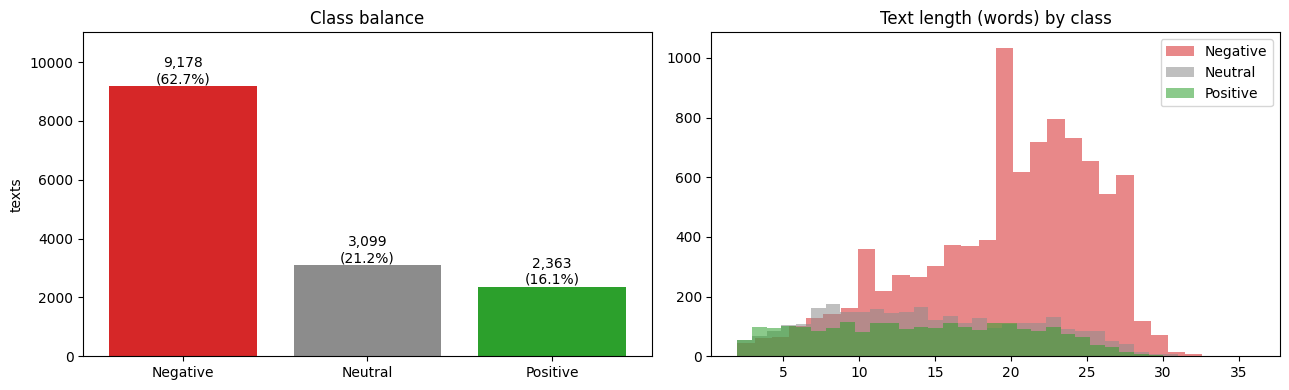

Missing text: 0, missing label: 0
Duplicate texts: 213 (texts with conflicting labels: 25)
The classes are imbalanced, so we report macro precision / recall / F1, not only accuracy.


In [ ]:
counts = pd.Series(summary["class_counts"])
lengths = raw.assign(words=raw["text"].astype(str).str.split().str.len())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(counts.index, counts.values, color=[COLORS.get(c) for c in counts.index])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({100 * v / counts.sum():.1f}%)", ha="center", va="bottom")
axes[0].set_title("Class balance"); axes[0].set_ylabel("texts"); axes[0].set_ylim(0, counts.max() * 1.2)
for lab in counts.index:
    axes[1].hist(lengths.loc[lengths["label"] == lab, "words"], bins=30, alpha=0.55, label=lab, color=COLORS.get(lab))
axes[1].set_title("Text length (words) by class"); axes[1].legend()
plt.tight_layout(); plt.show()

dups = raw[raw["text"].duplicated(keep=False)]
conflicting = dups.groupby("text")["label"].nunique().gt(1).sum()
print(f"Missing text: {summary['missing_text']}, missing label: {summary['missing_label']}")
print(f"Duplicate texts: {summary['duplicate_texts']} (texts with conflicting labels: {conflicting})")
print("The classes are imbalanced, so we report macro precision / recall / F1, not only accuracy.")

## 3. Preprocess the text and split into train / test
Lower-case, remove URLs and @mentions, expand contractions (*isn't → is not*), keep letters only,
remove stopwords **but keep negation words**, lemmatise.

In [ ]:
examples = [
    "@united The flight was NOT good, we waited 3 hours!!! http://t.co/abc",
    "I don't like the new seats :(",
    "@VirginAmerica thanks sooooo much, the crew were amazing :)",
    "Isn't there a later flight to Boston?",
]
display(pd.DataFrame({"original": examples, "cleaned": [clean_text(t) for t in examples]}))
print("Negation words kept:", sorted(NEGATIONS))

,original,cleaned
0,"@united The flight was NOT good, we waited 3 hours!!! http://t.co/abc",flight not good waited hour
1,I don't like the new seats :(,not like new seat sadface
2,"@VirginAmerica thanks sooooo much, the crew were amazing :)",thanks soo much crew amazing smileface
3,Isn't there a later flight to Boston?,not later flight boston


Negation words kept: ['barely', 'cannot', 'hardly', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'nowhere', 'without']


In [ ]:
df = add_clean_column(prepare_dataset(raw))
empty = (df["clean"] == "").sum()
df = df[df["clean"] != ""].reset_index(drop=True)
print(f"Rows after removing missing / duplicate texts: {len(df) + empty:,}; texts empty after cleaning: {empty}; used: {len(df):,}")

train_df, test_df = split_data(df, test_size=0.2, seed=42)
dist = pd.DataFrame({"train": train_df["label"].value_counts(normalize=True),
                     "test": test_df["label"].value_counts(normalize=True)}).reindex(LABELS).round(3)
print(f"Train: {len(train_df):,}  Test: {len(test_df):,}  (stratified, so class shares match)")
dist

Rows after removing missing / duplicate texts: 14,427; texts empty after cleaning: 18; used: 14,409
Train: 11,527  Test: 2,882  (stratified, so class shares match)


,train,test
label,,
Negative,0.630,0.630
Neutral,0.211,0.211
Positive,0.159,0.159


## 4. TF-IDF features
Each text becomes a sparse vector of TF-IDF weights over unigrams and bigrams. Bigrams such as
*not good* let the model learn negation.

In [ ]:
tfidf_demo = make_tfidf()
X_demo = tfidf_demo.fit_transform(train_df["clean"])
feats = tfidf_demo.get_feature_names_out()
print("Matrix shape (texts x features):", X_demo.shape)
print(f"Non-zero values: {X_demo.nnz:,} ({100 * X_demo.nnz / np.prod(X_demo.shape):.3f}% - very sparse)")
print("Example bigrams with 'not':", [f for f in feats if f.startswith("not ")][:15])

Matrix shape (texts x features): (11527, 13636)
Non-zero values: 133,275 (0.085% - very sparse)
Example bigrams with 'not': ['not aa', 'not able', 'not accept', 'not acceptable', 'not access', 'not accommodate', 'not actually', 'not add', 'not address', 'not addressed', 'not afford', 'not agent', 'not airport', 'not allow', 'not allowed']


## 5. Train and compare Multinomial Naive Bayes and Logistic Regression
Each model is a pipeline *TF-IDF → classifier*. Hyper-parameters are tuned with 5-fold
cross-validation on the training set (scoring = macro F1). The best model is chosen by the
cross-validation score, so the test set is only used for the final, unbiased report.

In [ ]:
results = train_models(train_df)
results = evaluate_models(results, test_df)
best = choose_best(results)
print("\nBest model:", MODEL_NAMES[best])
comparison = comparison_table(results)
comparison

Multinomial Naive Bayes    CV macro-F1 = 0.7067  best params = {'clf__alpha': 0.3, 'clf__fit_prior': False, 'tfidf__ngram_range': (1, 2)}  (25.5s)
Logistic Regression        CV macro-F1 = 0.7284  best params = {'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}  (63.7s)

Best model: Logistic Regression


,CV macro-F1,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
Model,,,,,,
Multinomial Naive Bayes,0.7067,0.7641,0.6945,0.6978,0.6957,0.7629
Logistic Regression,0.7284,0.7731,0.7109,0.7402,0.7236,0.7781


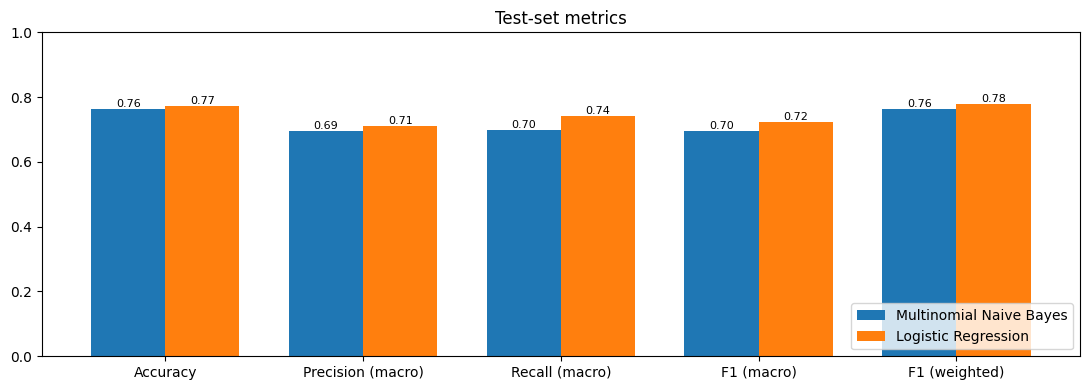

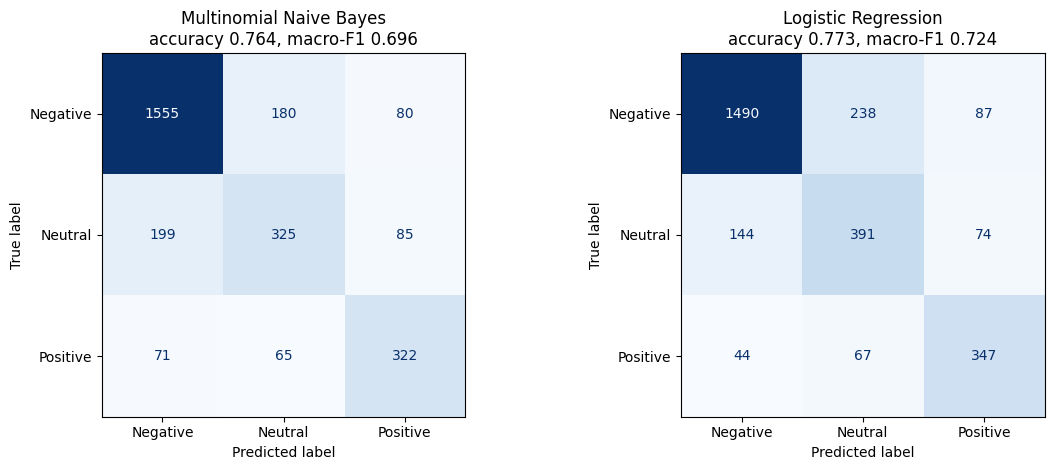

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ax = comparison.drop(columns=["CV macro-F1"]).T.plot.bar(figsize=(11, 4), rot=0, ylim=(0, 1), width=0.75)
ax.set_title("Test-set metrics"); ax.legend(loc="lower right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 4.8))
for ax, (name, res) in zip(np.atleast_1d(axes), results.items()):
    t = res["test"]
    ConfusionMatrixDisplay(np.array(t["confusion_matrix"]), display_labels=t["labels"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{MODEL_NAMES[name]}\naccuracy {t['accuracy']:.3f}, macro-F1 {t['f1_macro']:.3f}")
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import classification_report

for name, res in results.items():
    print("=" * 70, "\n", MODEL_NAMES[name], "| best params:", res["best_params"])
    print(classification_report(test_df["label"], res["test_pred"], digits=3, zero_division=0))

 Multinomial Naive Bayes | best params: {'clf__alpha': 0.3, 'clf__fit_prior': False, 'tfidf__ngram_range': [1, 2]}
              precision    recall  f1-score   support

    Negative      0.852     0.857     0.854      1815
     Neutral      0.570     0.534     0.551       609
    Positive      0.661     0.703     0.681       458

    accuracy                          0.764      2882
   macro avg      0.694     0.698     0.696      2882
weighted avg      0.762     0.764     0.763      2882

 Logistic Regression | best params: {'clf__C': 1, 'clf__class_weight': 'balanced', 'tfidf__ngram_range': [1, 2]}
              precision    recall  f1-score   support

    Negative      0.888     0.821     0.853      1815
     Neutral      0.562     0.642     0.599       609
    Positive      0.683     0.758     0.718       458

    accuracy                          0.773      2882
   macro avg      0.711     0.740     0.724      2882
weighted avg      0.786     0.773     0.778      2882



In [ ]:
# What did Logistic Regression learn? Highest-weighted words / bigrams per class.
lr = results["logistic_regression"]["model"]
names = lr.named_steps["tfidf"].get_feature_names_out()
coef = lr.named_steps["clf"].coef_
if coef.shape[0] == 1:  # binary dataset: one weight vector
    coef = np.vstack([-coef[0], coef[0]])
top = {cls: names[np.argsort(coef[i])[::-1][:15]] for i, cls in enumerate(lr.classes_)}
pd.DataFrame(top)

,Negative,Neutral,Positive
0,not,hi,thanks
1,hour,dm,great
2,no,question,thank
3,hr,possible,love
4,worst,policy,awesome
5,delayed,avgeek,smileface
6,hold,tomorrow,best
7,bag,no not,amazing
8,customer,need,good
9,luggage,delay cancelled,thx


## 6. Save the models (used by the dashboard)

In [ ]:
dataset_info = {
    "source": raw.attrs.get("source"),
    "raw_summary": summary,
    "rows_used": int(len(df)),
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "test_size": 0.2,
    "train_class_counts": {k: int(v) for k, v in train_df["label"].value_counts().items()},
}
out = save_artifacts(results, best, test_df, dataset_info)
for f in sorted(out.iterdir()):
    print(f"{f.name:<30} {f.stat().st_size / 1024:8.1f} KB")

logistic_regression.joblib        636.7 KB
metrics.json                        4.9 KB
naive_bayes.joblib                956.1 KB
test_predictions.csv              532.9 KB


## 7. Test with new examples and review incorrect predictions

In [ ]:
predictor = SentimentPredictor(results[best]["model"], best)
new_examples = [
    "The crew were fantastic and we landed early, thank you!",
    "Worst airline ever. Lost my bag and nobody cares.",
    "What time does the 7am flight to Denver start boarding?",
    "The food was not good and the seat was not comfortable.",
    "I love this phone, the battery lasts all day.",
    "The package arrived on Tuesday.",
]
predictor.predict(new_examples)[["text", "sentiment", "confidence", "p_Negative", "p_Neutral", "p_Positive"]].round(3)

,text,sentiment,confidence,p_Negative,p_Neutral,p_Positive
0,"The crew were fantastic and we landed early, thank you!",Positive,0.971,0.007,0.021,0.971
1,Worst airline ever. Lost my bag and nobody cares.,Negative,0.973,0.973,0.005,0.023
2,What time does the 7am flight to Denver start boarding?,Neutral,0.528,0.324,0.528,0.148
3,The food was not good and the seat was not comfortable.,Negative,0.635,0.635,0.160,0.205
4,"I love this phone, the battery lasts all day.",Positive,0.592,0.250,0.157,0.592
5,The package arrived on Tuesday.,Negative,0.455,0.455,0.380,0.166


In [ ]:
pred = results[best]["test_pred"]
errors = test_df.assign(predicted=pred)[lambda d: d["label"] != d["predicted"]]
print(f"{len(errors):,} of {len(test_df):,} test texts misclassified ({100 * len(errors) / len(test_df):.1f}%)")
display(errors.groupby(["label", "predicted"]).size().sort_values(ascending=False).to_frame("count"))
errors[["text", "label", "predicted"]].sample(min(12, len(errors)), random_state=0)

654 of 2,882 test texts misclassified (22.7%)


count
label    predicted       
Negative Neutral      238
Neutral  Negative     144
Negative Positive      87
Neutral  Positive      74
Positive Neutral       67
         Negative      44

,text,label,predicted
2345,@SouthwestAir I have a voucher w swa that expires 4/10. An extension would be a lot of luv,Negative,Neutral
2147,@AmericanAir Thx! I hope so. IAH to DFW to OKC has turned out to be a LONG trip today and I have to work tomorrow.,Positive,Neutral
73,@USAirways &amp; @AmericanAir: 1 flight Cancelled Flightled yesterday and now a delay today has robbed my daughter o...,Neutral,Negative
1092,@SouthwestAir is making dreams come true with their #DestinationDragons scavenger hunt! You can win a chance to see ...,Positive,Neutral
357,@SouthwestAir and thx for not responding,Negative,Positive
546,"@AmericanAir and @CVGairport get it together, perfect combination for delays and Cancelled Flightlations",Neutral,Negative
2532,"@VirginAmerica Just trying to book tickets to NYC and facing super fun broken styling. Don't worry, I'll keep trying :)",Negative,Positive
2326,@united Boeing 777 Star Alliance short finals @Heathrowairport 27L on an amazing winters morning #777 #Avgeek http:/...,Positive,Neutral
1453,@AmericanAir we're all being told by emergency services to stay home for the next 24-48 hours.,Neutral,Negative
2121,@SouthwestAir 8FKQW is the conf #. Thanks for the reply,Neutral,Positive


Typical mistakes: **Neutral** is the hardest class (questions and factual tweets often contain complaint words),
sarcasm (*"great, another delay"*) and tweets that mix praise and complaints. This is why macro-F1 is lower than accuracy.

## 8. Enhancement: Aspect-Based Sentiment Analysis (ABSA)
Instead of one sentiment for the whole review, find the sentiment about each aspect. The review is split into
clauses at sentence ends and contrast words (*but, however, although…*), aspect keywords are found in each
clause, and the trained model predicts each clause's sentiment.

In [ ]:
for review in [
    "The camera is excellent, but the battery is poor.",
    "Staff were friendly and helpful. However the food was cold and the seats were uncomfortable!",
    "Delivery was quick, although the price is too expensive.",
]:
    print("Review:", review)
    display(analyse_aspects(review, predictor)[["aspect", "clause", "sentiment", "confidence"]].round(3))

Review: The camera is excellent, but the battery is poor.


,aspect,clause,sentiment,confidence
0,Camera,The camera is excellent,Positive,0.756
1,Battery,the battery is poor,Negative,0.534


Review: Staff were friendly and helpful. However the food was cold and the seats were uncomfortable!


,aspect,clause,sentiment,confidence
0,Service / Staff,Staff were friendly and helpful,Positive,0.827
1,Seat / Comfort,the food was cold and the seats were uncomfortable,Negative,0.404
2,Food / Drink,the food was cold and the seats were uncomfortable,Negative,0.404


Review: Delivery was quick, although the price is too expensive.


,aspect,clause,sentiment,confidence
0,Delivery,Delivery was quick,Positive,0.469
1,Price / Value,the price is too expensive,Negative,0.617


## 9. Launch the Streamlit dashboard
Starts `streamlit run app.py` in the background and opens a free Cloudflare tunnel, then prints a public
`https://….trycloudflare.com` link. Open it in a new browser tab (if it does not load straight away, wait
10-20 seconds and refresh). The dashboard keeps running while this notebook session is active.

Tabs: **Single review** · **CSV upload** (counts, percentages, charts, common words, themes, download) ·
**Aspect analysis** · **Model performance** (comparison, confusion matrices, per-class results, error analysis).

In [ ]:
import re, subprocess, time, urllib.request

PORT = 8501

def wait_for(url, seconds=60):
    for _ in range(seconds):
        try:
            urllib.request.urlopen(url, timeout=2)
            return True
        except Exception:
            time.sleep(1)
    return False

subprocess.run(["pkill", "-f", "streamlit run app.py"], check=False)
subprocess.run(["pkill", "-f", "cloudflared tunnel"], check=False)
time.sleep(1)

streamlit_proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py", "--server.port", str(PORT),
     "--server.headless", "true", "--browser.gatherUsageStats", "false"],
    stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)
if not wait_for(f"http://localhost:{PORT}/_stcore/health"):
    print(open("streamlit.log").read())
    raise RuntimeError("Streamlit did not start - see the log above")
print("Streamlit is running on port", PORT)

if IN_COLAB or IN_KAGGLE:
    if not os.path.exists("cloudflared"):
        urllib.request.urlretrieve(
            "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
            "cloudflared")
        os.chmod("cloudflared", 0o755)
    tunnel_proc = subprocess.Popen(
        ["./cloudflared", "tunnel", "--url", f"http://localhost:{PORT}", "--no-autoupdate"],
        stdout=open("cloudflared.log", "w"), stderr=subprocess.STDOUT)
    public_url = None
    for _ in range(60):
        time.sleep(1)
        found = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("cloudflared.log").read())
        if found:
            public_url = found.group(0)
            break
    if public_url:
        print("\n🚀 Dashboard:", public_url)
    else:
        print(open("cloudflared.log").read()[-2000:])
        print("Tunnel did not start. On Kaggle check that Settings -> Internet is on.")
    if IN_COLAB:
        from google.colab import output
        print("Alternative link through Colab's own proxy:")
        output.serve_kernel_port_as_window(PORT, anchor_text="Open dashboard (Colab proxy)")
else:
    print(f"Open http://localhost:{PORT} in your browser")

Streamlit is running on port 8501

🚀 Dashboard: https://arm-swimming-mac-automotive.trycloudflare.com
Alternative link through Colab's own proxy:
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
# Run this to stop the dashboard.
subprocess.run(["pkill", "-f", "streamlit run app.py"], check=False)
subprocess.run(["pkill", "-f", "cloudflared tunnel"], check=False)
print("Stopped")

Stopped


## 10. Download the project with the trained models (optional)
On Colab the zip downloads automatically; on Kaggle it appears under **Output** (`/kaggle/working`).

In [ ]:
import zipfile
from pathlib import Path

zip_path = Path(PROJECT).parent / "sentiment-dashboard-trained.zip"
skip = {"cloudflared", "streamlit.log", "cloudflared.log"}
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in Path(PROJECT).rglob("*"):
        if f.is_file() and f.name not in skip and "__pycache__" not in f.parts and ".ipynb_checkpoints" not in f.parts:
            z.write(f, Path("sentiment-dashboard") / f.relative_to(PROJECT))
print("Saved", zip_path, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))

Saved /content/sentiment-dashboard-trained.zip (2.5 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>